# Estudio 5 — Pulso de velocidad: ¿hace falta la opción C?

**Pregunta:** el estudio 3 mostró que, con 8 decisiones por segundo, los peces que nadan a más de unos 1.6 BL/s se chocan y pierden el orden. ¿Ese daño es **pasajero** (el grupo se recupera cuando vuelve a ir lento) o **permanente** (el grupo se rompe y no se vuelve a juntar)?

- **Parte A:** un pulso rápido (2.6 o 5 BL/s, durante 2, 10, 30 o 60 s) entre dos tramos lentos de 60 s a 1 BL/s. Medimos cuánto tarda el grupo en recuperarse.
- **Parte B:** en una sola simulación larga, subimos la velocidad de 0.2 a 5 BL/s y la volvemos a bajar. ¿Se "acuerda" el grupo de haber ido rápido?

No programamos la opción C: con un largo de paso fijo, el grupo se porta igual a cualquier velocidad (estudio 3). Aquí solo medimos qué tan grave es la opción A (el modelo de Puckett tal cual).

## Preparación

In [1]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the checks folder (the one with study_code/study_tools.py) and let Python import from study_code.
CHECKS_FOLDER = Path.cwd()
while not (CHECKS_FOLDER / "study_code" / "study_tools.py").is_file():
    if CHECKS_FOLDER == CHECKS_FOLDER.parent:
        raise FileNotFoundError("study_code/study_tools.py was not found in this folder or any parent folder.")
    CHECKS_FOLDER = CHECKS_FOLDER.parent
TOOLS_FOLDER = CHECKS_FOLDER / "study_code"
if str(TOOLS_FOLDER) not in sys.path:
    sys.path.insert(0, str(TOOLS_FOLDER))

import study_tools
from study_tools import (
    PUCKETT_SETTINGS, A0_COLOR, PUCKETT_COLOR,
    average, build_model, change_settings, fraction_of_moments, has_collision,
    load_results, measure_moment, smallest, study_2_option,
)

# Where this study keeps its results and figures.
STUDY_FOLDER = CHECKS_FOLDER / "trial_eight_speed_pulse"
DATA_FOLDER = STUDY_FOLDER / "data"
FIGURE_FOLDER = STUDY_FOLDER / "figures"
DATA_FOLDER.mkdir(exist_ok=True)
FIGURE_FOLDER.mkdir(exist_ok=True)

SEEDS = list(range(10))
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

### El modelo

El modelo de Puckett (A4) con el grupo empezando junto, en el 25 % central de la arena. Comprobamos que los valores son los del README antes de correr nada.

In [2]:
PULSE_SETTINGS = change_settings(PUCKETT_SETTINGS, "A4, inicio junto", {"initial_spread": 0.25})

# The values the README asks for. If one of them is different, stop here.
EXPECTED_VALUES = {
    "n_fish": 20,
    "repulsion_radius": 0.5,
    "orientation_radius": 3.0,
    "attraction_radius": 5.5,
    "fov_degrees": 270.0,
    "turn_per_decision": 1.75,
    "noise_per_decision": 0.01,
    "arena": 28.0,
    "dt": 0.125,
    "speed": 1.0,
    "initial_spread": 0.25,
    "rules": "repulsion+orientation+attraction",
}
for key in EXPECTED_VALUES:
    print(f"{key:20s} {PULSE_SETTINGS[key]}")
    assert PULSE_SETTINGS[key] == EXPECTED_VALUES[key], f"{key} is not the README value"

# speed_gain must be 0: each fish keeps the speed we give it.
print(f"{'speed_gain':20s} {study_2_option(PULSE_SETTINGS, 'speed_gain')}")
assert study_2_option(PULSE_SETTINGS, "speed_gain") == 0

n_fish               20
repulsion_radius     0.5
orientation_radius   3.0
attraction_radius    5.5
fov_degrees          270.0
turn_per_decision    1.75
noise_per_decision   0.01
arena                28.0
dt                   0.125
speed                1.0
initial_spread       0.25
rules                repulsion+orientation+attraction
speed_gain           0.0


### Definiciones fijadas antes de correr

Copiadas del README, sin cambios:

- Un **momento bueno** es una decisión en la que el grupo más grande tiene al menos 19 de los 20 peces (95 %), la polarización es de 0.9 o más y no hay ningún choque (ningún par a menos de 0.25 BL).
- El grupo **se recuperó** cuando hay **40 momentos buenos seguidos** (5 s).
- **Tiempo de recuperación** = segundos desde que termina el pulso hasta que empiezan esos 40 momentos. Los 40 momentos tienen que caber dentro de los 60 s de recuperación, así que el tiempo más largo posible es 55 s.
- El grupo **está listo** al empezar el pulso si las últimas 40 decisiones del calentamiento son todas buenas.
- La regla de decisión cuenta **las 10 seeds** de cada combinación, también las que no estaban listas (el README dice "9 de 10 seeds"). Las que no estaban listas se muestran aparte.

In [3]:
GOOD_LARGEST_FRACTION = 0.95    # at least 19 of the 20 fish in the largest group
GOOD_POLARIZATION = 0.9         # almost all fish swim the same way
GOOD_SECONDS = 5                # a recovery needs 5 seconds of good moments in a row

NORMAL_SPEED = 1.0              # BL/s during the warm-up and the recovery
WARM_UP_SECONDS = 60
RECOVERY_SECONDS = 60
PULSE_SPEEDS = [2.6, 5.0]       # BL/s
PULSE_DURATIONS = [2, 10, 30, 60]   # seconds

# The control has no pulse: always 1 BL/s. We store it as pulse speed 1.0 and duration 0 s.
CONTROL_SPEED = 1.0
CONTROL_SECONDS = 0

### Funciones de ayuda

Pasar de segundos a decisiones, y cambiar la velocidad de todos los peces entre dos pasos.

In [4]:
def seconds_to_decisions(seconds, dt):
    """Number of decisions in `seconds` (8 per second when dt = 0.125 s)."""
    return round(seconds / dt)


def set_speed(model, speed):
    """Give every fish the same new speed.

    Why this works: with speed_gain = 0, each fish reads fish.speed at every decision
    (new position = position + direction * speed * dt), and model.dt stays 0.125 s.
    So from the next decision on, the step length is speed * 0.125 BL.
    base_speed and next_speed are changed too, so the three speed values always agree.
    """
    for fish in model.agents:
        fish.speed = speed
        fish.base_speed = speed
        fish.next_speed = speed


GOOD_STREAK = seconds_to_decisions(GOOD_SECONDS, PULSE_SETTINGS["dt"])
print("Good moments in a row needed for a recovery:", GOOD_STREAK)

Good moments in a row needed for a recovery: 40


¿Es bueno este momento? ¿Cuándo se recuperó el grupo? ¿Estaba listo al empezar el pulso?

In [5]:
def is_good_moment(moment):
    """True when the group is together, ordered and without any collision."""
    together = moment["largest_fraction"] >= GOOD_LARGEST_FRACTION
    ordered = moment["polarization"] >= GOOD_POLARIZATION
    no_collision = moment["closest_pair"] >= study_tools.COLLISION_DISTANCE
    return together and ordered and no_collision


def all_good(moments):
    """True when every moment in the list is a good moment."""
    for moment in moments:
        if not is_good_moment(moment):
            return False
    return True


def recovery_time(moments_after_pulse, dt):
    """Seconds from the end of the pulse until GOOD_STREAK good moments in a row start.

    moments_after_pulse[i] is measured after decision i + 1 of the recovery,
    and that decision starts i * dt seconds after the end of the pulse.
    The good moments must all fit inside the recovery window.
    Returns None if the group never recovers.
    """
    last_start = len(moments_after_pulse) - GOOD_STREAK
    for start in range(last_start + 1):
        if all_good(moments_after_pulse[start:start + GOOD_STREAK]):
            return start * dt
    return None


def ready_at_pulse_start(warm_up_moments):
    """True when the last GOOD_STREAK decisions of the warm-up are all good."""
    return all_good(warm_up_moments[-GOOD_STREAK:])

### Una corrida con pulso

Calentamiento (60 s a 1 BL/s), pulso (todos los peces a la velocidad del pulso) y recuperación (60 s a 1 BL/s). Medimos el grupo en **cada** decisión.

In [6]:
def run_phase(model, speed, n_decisions):
    """Swim n_decisions decisions at `speed` and measure the group after every decision."""
    set_speed(model, speed)
    moments = []
    for _ in range(n_decisions):
        model.step()
        moments.append(measure_moment(model))
    return moments


def timeseries_rows(seed, pulse_speed, pulse_seconds, dt, phases):
    """One row per decision: the time since the start of the run and the measurements."""
    rows = []
    decision = 0
    for phase_name, moments in phases:
        for moment in moments:
            decision += 1
            rows.append({
                "seed": seed,
                "pulse_speed": pulse_speed,
                "pulse_seconds": pulse_seconds,
                "time_s": decision * dt,
                "phase": phase_name,
                "polarization": moment["polarization"],
                "rotation": moment["rotation"],
                "largest_fraction": moment["largest_fraction"],
                "closest_pair": moment["closest_pair"],
                "nnd": moment["nnd"],
                "collision": has_collision(moment),
            })
    return rows


def summary_row(seed, pulse_speed, pulse_seconds, dt, warm_up, pulse, recovery):
    """One row per run: was the group ready, did it recover, and how bad was the pulse."""
    time_to_recover = recovery_time(recovery, dt)
    row = {
        "seed": seed,
        "pulse_speed": pulse_speed,
        "pulse_seconds": pulse_seconds,
        "ready_at_pulse_start": ready_at_pulse_start(warm_up),
        "recovery_time_s": np.nan if time_to_recover is None else time_to_recover,
        "recovered_within_10_s": time_to_recover is not None and time_to_recover <= 10,
        "recovered_within_60_s": time_to_recover is not None,
    }

    # How bad was the pulse? (The control has no pulse, so these are empty there.)
    if len(pulse) > 0:
        row["pulse_collision_fraction"] = fraction_of_moments(pulse, has_collision)
        row["pulse_min_pair_distance"] = smallest(pulse, "closest_pair")
        row["pulse_min_largest_fraction"] = smallest(pulse, "largest_fraction")
        row["pulse_mean_polarization"] = average(pulse, "polarization")
    else:
        row["pulse_collision_fraction"] = np.nan
        row["pulse_min_pair_distance"] = np.nan
        row["pulse_min_largest_fraction"] = np.nan
        row["pulse_mean_polarization"] = np.nan

    # Extra (not in the README): the state of the group in the last 5 s of the recovery.
    # It tells WHY a run did not recover: split group, low order, or collisions.
    last_moments = recovery[-GOOD_STREAK:]
    row["end_largest_fraction"] = average(last_moments, "largest_fraction")
    row["end_polarization"] = average(last_moments, "polarization")
    row["end_collision_fraction"] = fraction_of_moments(last_moments, has_collision)
    return row


def run_pulse(settings, seed, pulse_speed, pulse_seconds):
    """Warm-up, pulse and recovery in one simulation. Returns (rows per decision, summary row)."""
    start_time = time.perf_counter()
    dt = settings["dt"]
    model = build_model(settings, seed)

    warm_up = run_phase(model, NORMAL_SPEED, seconds_to_decisions(WARM_UP_SECONDS, dt))
    pulse = run_phase(model, pulse_speed, seconds_to_decisions(pulse_seconds, dt))
    recovery = run_phase(model, NORMAL_SPEED, seconds_to_decisions(RECOVERY_SECONDS, dt))

    phases = [("warm_up", warm_up), ("pulse", pulse), ("recovery", recovery)]
    rows = timeseries_rows(seed, pulse_speed, pulse_seconds, dt, phases)
    summary = summary_row(seed, pulse_speed, pulse_seconds, dt, warm_up, pulse, recovery)
    summary["n_decisions"] = len(rows)
    summary["runtime_s"] = time.perf_counter() - start_time
    return rows, summary

Correr muchas configuraciones y guardar los resultados. Como en los estudios anteriores, si los archivos ya existen se cargan (salvo que `study_tools.RERUN = True`).

In [7]:
def run_pulse_configurations(configurations, timeseries_path, summary_path):
    """Run every (pulse_speed, pulse_seconds) with every seed, or load the saved files."""
    if timeseries_path.exists() and summary_path.exists() and not study_tools.RERUN:
        print(f"Loaded saved results from {summary_path.name} and {timeseries_path.name}.")
        return load_results(timeseries_path), load_results(summary_path)

    all_rows = []
    summaries = []
    start_time = time.perf_counter()
    for number, (pulse_speed, pulse_seconds) in enumerate(configurations, start=1):
        recovered = 0
        for seed in SEEDS:
            rows, summary = run_pulse(PULSE_SETTINGS, seed, pulse_speed, pulse_seconds)
            all_rows.extend(rows)
            summaries.append(summary)
            if summary["recovered_within_10_s"]:
                recovered += 1
        minutes = (time.perf_counter() - start_time) / 60
        print(f"[{number}/{len(configurations)}] {pulse_speed} BL/s for {pulse_seconds} s: "
              f"recovered within 10 s in {recovered} of {len(SEEDS)} seeds ({minutes:.1f} min so far)",
              flush=True)

    pd.DataFrame(all_rows).to_csv(timeseries_path, index=False)
    pd.DataFrame(summaries).to_csv(summary_path, index=False)
    # Return the saved files, so a fresh run and a later reload give exactly the same numbers.
    return load_results(timeseries_path), load_results(summary_path)

## Primero, el control (sin pulso)

Siempre a 1 BL/s. Medimos su "recuperación" desde el final del calentamiento. Sirve para ver cuánto falla el criterio por puro azar. El control se guarda en sus propios archivos porque se corre antes que los pulsos.

In [8]:
control_timeseries, control_summary = run_pulse_configurations(
    [(CONTROL_SPEED, CONTROL_SECONDS)],
    DATA_FOLDER / "control_timeseries.csv.gz",
    DATA_FOLDER / "control_summary.csv",
)
control_summary[["seed", "ready_at_pulse_start", "recovery_time_s", "recovered_within_10_s",
                 "recovered_within_60_s", "end_largest_fraction", "end_polarization",
                 "end_collision_fraction"]]

Loaded saved results from control_summary.csv and control_timeseries.csv.


,seed,ready_at_pulse_start,recovery_time_s,recovered_within_10_s,recovered_within_60_s,end_largest_fraction,end_polarization,end_collision_fraction
0,0,False,1.375,True,True,1.00,0.997,0.0
1,1,False,0.000,True,True,1.00,0.998,0.0
2,2,True,0.000,True,True,1.00,0.998,0.0
3,3,True,2.375,True,True,1.00,1.000,0.0
4,4,True,0.000,True,True,1.00,0.998,0.0
5,5,True,0.000,True,True,0.95,0.918,0.0
6,6,True,0.000,True,True,1.00,1.000,0.0
7,7,True,0.000,True,True,1.00,1.000,0.0
8,8,True,0.000,True,True,1.00,1.000,0.0
9,9,True,4.375,True,True,1.00,1.000,0.0


**Comprobación del README:** si menos de 9 de 10 seeds del control se recuperan en 10 s, el criterio es demasiado estricto. En ese caso paramos aquí y avisamos (no lo cambiamos por nuestra cuenta).

In [9]:
control_ready = int(control_summary["ready_at_pulse_start"].sum())
control_recovered = int(control_summary["recovered_within_10_s"].sum())
print(f"Control: {control_ready} of {len(SEEDS)} seeds ready at the end of the warm-up.")
print(f"Control: {control_recovered} of {len(SEEDS)} seeds recover within 10 s.")

if control_recovered < 9:
    raise RuntimeError("STOP: fewer than 9 of 10 control seeds recover within 10 s. "
                       "The recovery criterion may be too strict. Ask the group before going on.")
print("The control passes: the criterion is not too strict.")

Control: 8 of 10 seeds ready at the end of the warm-up.
Control: 10 of 10 seeds recover within 10 s.
The control passes: the criterion is not too strict.


**¿Cuánto van a tardar los pulsos?** Lo estimamos con el tiempo por decisión del control.

In [10]:
dt = PULSE_SETTINGS["dt"]
seconds_per_decision = control_summary["runtime_s"].sum() / control_summary["n_decisions"].sum()

# Decisions of all pulse runs: warm-up + pulse + recovery, for every configuration and seed.
pulse_decisions = 0
for pulse_speed in PULSE_SPEEDS:
    for pulse_seconds in PULSE_DURATIONS:
        one_run = seconds_to_decisions(WARM_UP_SECONDS + pulse_seconds + RECOVERY_SECONDS, dt)
        pulse_decisions += one_run * len(SEEDS)

# Part B: 60 s warm-up + 16 speed values of 30 s each, for every seed (an upper estimate,
# because Part B only measures the last third of each value).
ramp_decisions = seconds_to_decisions(60 + 16 * 30, dt) * len(SEEDS)

print(f"Time per decision (with a measurement): {1000 * seconds_per_decision:.2f} ms")
print(f"Estimated time, pulses: {pulse_decisions * seconds_per_decision / 60:.1f} min")
print(f"Estimated time, Part B: {ramp_decisions * seconds_per_decision / 60:.1f} min (at most)")

Time per decision (with a measurement): 0.83 ms
Estimated time, pulses: 1.3 min
Estimated time, Part B: 0.6 min (at most)


## Parte A — Los pulsos

2 velocidades × 4 duraciones × 10 seeds = 80 corridas.

In [11]:
PULSE_CONFIGURATIONS = []
for pulse_speed in PULSE_SPEEDS:
    for pulse_seconds in PULSE_DURATIONS:
        PULSE_CONFIGURATIONS.append((pulse_speed, pulse_seconds))

pulse_timeseries, pulse_summary = run_pulse_configurations(
    PULSE_CONFIGURATIONS,
    DATA_FOLDER / "pulse_timeseries.csv.gz",
    DATA_FOLDER / "pulse_summary.csv",
)

# The control and the pulses together (90 runs), for the tables and figures.
all_summaries = pd.concat([control_summary, pulse_summary], ignore_index=True)
all_timeseries = pd.concat([control_timeseries, pulse_timeseries], ignore_index=True)
print("Runs:", len(all_summaries))

Loaded saved results from pulse_summary.csv and pulse_timeseries.csv.
Runs: 90


### La tabla de la decisión

Para cada combinación: cuántas seeds estaban listas al empezar el pulso, cuántas se recuperaron en 10 s y en 60 s, la mediana del tiempo de recuperación y el tiempo con choques durante el pulso. Si una corrida no se recuperó, cuenta como "más de 55 s" en la mediana.

In [12]:
def median_recovery_text(runs):
    """Median recovery time over all seeds; a run that never recovered counts as the longest."""
    times = []
    for value in runs["recovery_time_s"]:
        if np.isnan(value):
            times.append(np.inf)
        else:
            times.append(value)
    median = np.median(times)
    if np.isinf(median):
        return "> 55 s"
    return f"{median:.1f} s"


def decision_table(summaries):
    """One row per (pulse_speed, pulse_seconds), in the order in which they were run."""
    rows = []
    configurations = [(CONTROL_SPEED, CONTROL_SECONDS)] + PULSE_CONFIGURATIONS
    for pulse_speed, pulse_seconds in configurations:
        runs = summaries[(summaries["pulse_speed"] == pulse_speed)
                         & (summaries["pulse_seconds"] == pulse_seconds)]
        if pulse_seconds == 0:
            name = "control (sin pulso)"
            collisions = "-"
        else:
            name = f"{pulse_speed} BL/s, {pulse_seconds} s"
            collisions = f"{100 * runs['pulse_collision_fraction'].mean():.0f} %"
        rows.append({
            "configuración": name,
            "listas al empezar": f"{int(runs['ready_at_pulse_start'].sum())}/{len(runs)}",
            "recuperadas en 10 s": f"{int(runs['recovered_within_10_s'].sum())}/{len(runs)}",
            "recuperadas en 60 s": f"{int(runs['recovered_within_60_s'].sum())}/{len(runs)}",
            "mediana del tiempo": median_recovery_text(runs),
            "tiempo con choque en el pulso": collisions,
        })
    return pd.DataFrame(rows)


table = decision_table(all_summaries)
table

,configuración,listas al empezar,recuperadas en 10 s,recuperadas en 60 s,mediana del tiempo,tiempo con choque en el pulso
0,control (sin pulso),8/10,10/10,10/10,0.0 s,-
1,"2.6 BL/s, 2 s",8/10,10/10,10/10,3.6 s,10 %
2,"2.6 BL/s, 10 s",8/10,8/10,10/10,2.2 s,17 %
3,"2.6 BL/s, 30 s",8/10,8/10,9/10,1.5 s,17 %
4,"2.6 BL/s, 60 s",8/10,9/10,10/10,7.2 s,16 %
5,"5.0 BL/s, 2 s",8/10,8/10,10/10,5.8 s,25 %
6,"5.0 BL/s, 10 s",8/10,5/10,9/10,9.7 s,38 %
7,"5.0 BL/s, 30 s",8/10,3/10,9/10,18.4 s,38 %
8,"5.0 BL/s, 60 s",8/10,3/10,6/10,28.7 s,38 %


¿Qué tan grave fue cada pulso? Medias de las 10 seeds: distancia mínima entre dos peces, fracción mínima del grupo más grande y polarización media durante el pulso.

In [13]:
pulse_damage = pulse_summary.groupby(["pulse_speed", "pulse_seconds"], sort=False)[
    ["pulse_collision_fraction", "pulse_min_pair_distance", "pulse_min_largest_fraction",
     "pulse_mean_polarization"]].mean()
pulse_damage

pulse_collision_fraction  pulse_min_pair_distance  pulse_min_largest_fraction  pulse_mean_polarization
pulse_speed pulse_seconds                                                                                                        
2.6         2                                 0.100                    0.414                       0.995                    0.937
            10                                0.170                    0.048                       0.985                    0.898
            30                                0.166                    0.027                       0.970                    0.885
            60                                0.158                    0.022                       0.960                    0.887
5.0         2                                 0.250                    0.135                       0.995                    0.844
            10                                0.385                    0.044                       0.960                    0.746
            30                                0.376                    0.022                       0.905                    0.707
            60                                0.381                    0.017                       0.865                    0.688

### Seeds que no estaban listas al empezar el pulso

No se borran: se muestran aquí aparte, con su tiempo de recuperación.

In [14]:
not_ready = all_summaries[~all_summaries["ready_at_pulse_start"]]
print(f"{len(not_ready)} of {len(all_summaries)} runs were not ready at the start of the pulse.")
not_ready[["pulse_speed", "pulse_seconds", "seed", "recovery_time_s", "recovered_within_10_s",
           "recovered_within_60_s"]]

18 of 90 runs were not ready at the start of the pulse.


,pulse_speed,pulse_seconds,seed,recovery_time_s,recovered_within_10_s,recovered_within_60_s
0,1.0,0,0,1.375,True,True
1,1.0,0,1,0.000,True,True
10,2.6,2,0,0.000,True,True
11,2.6,2,1,4.250,True,True
20,2.6,10,0,1.750,True,True
21,2.6,10,1,2.625,True,True
30,2.6,30,0,NaN,False,False
31,2.6,30,1,2.500,True,True
40,2.6,60,0,6.875,True,True
41,2.6,60,1,0.000,True,True


### Aplicar la regla del README, tal cual

| Qué pasa | Decisión |
|---|---|
| Con 2.6 y con 5 BL/s, y para todas las duraciones, al menos 9 de 10 seeds se recuperan en 10 s o menos | **A es suficiente** |
| En alguna combinación, 2 seeds o más **no** se recuperan en 60 s | **A tiene un problema real** |
| Cualquier otro caso | **Zona gris** |

In [15]:
def apply_decision_rule(summaries):
    """Return the decision of the README and the reasons behind it."""
    every_combination_fast = True
    some_combination_broken = False
    reasons = []

    for pulse_speed, pulse_seconds in PULSE_CONFIGURATIONS:
        runs = summaries[(summaries["pulse_speed"] == pulse_speed)
                         & (summaries["pulse_seconds"] == pulse_seconds)]
        recovered_fast = int(runs["recovered_within_10_s"].sum())
        never_recovered = int((~runs["recovered_within_60_s"]).sum())
        name = f"{pulse_speed} BL/s, {pulse_seconds} s"

        if recovered_fast < 9:
            every_combination_fast = False
            reasons.append(f"{name}: only {recovered_fast} of {len(runs)} seeds recover within 10 s.")
        if never_recovered >= 2:
            some_combination_broken = True
            reasons.append(f"{name}: {never_recovered} seeds do not recover within 60 s.")

    if every_combination_fast:
        return "A es suficiente", ["Every combination: at least 9 of 10 seeds recover within 10 s."]
    if some_combination_broken:
        return "A tiene un problema real", reasons
    return "Zona gris", reasons


decision, reasons = apply_decision_rule(all_summaries)
print("Decision:", decision)
print("Why:")
for reason in reasons:
    print("  -", reason)

Decision: A tiene un problema real
Why:
  - 2.6 BL/s, 10 s: only 8 of 10 seeds recover within 10 s.
  - 2.6 BL/s, 30 s: only 8 of 10 seeds recover within 10 s.
  - 5.0 BL/s, 2 s: only 8 of 10 seeds recover within 10 s.
  - 5.0 BL/s, 10 s: only 5 of 10 seeds recover within 10 s.
  - 5.0 BL/s, 30 s: only 3 of 10 seeds recover within 10 s.
  - 5.0 BL/s, 60 s: only 3 of 10 seeds recover within 10 s.
  - 5.0 BL/s, 60 s: 4 seeds do not recover within 60 s.


### Extra: ¿por qué no se recuperaron?

Para cada combinación, el estado del grupo en los **últimos 5 s** de la recuperación (media de las 10 seeds): fracción del grupo más grande, polarización y tiempo con choque. Así sabemos si el grupo seguía **partido**, **desordenado** o **chocando**.

In [16]:
end_state = all_summaries.groupby(["pulse_speed", "pulse_seconds"], sort=False)[
    ["end_largest_fraction", "end_polarization", "end_collision_fraction"]].mean()
end_state

end_largest_fraction  end_polarization  end_collision_fraction
pulse_speed pulse_seconds                                                                
1.0         0                             0.995             0.991                   0.000
2.6         2                             0.995             0.981                   0.003
            10                            0.995             0.958                   0.003
            30                            0.990             0.951                   0.000
            60                            1.000             0.987                   0.000
5.0         2                             1.000             0.970                   0.000
            10                            0.980             0.956                   0.000
            30                            0.989             0.961                   0.000
            60                            0.950             0.892                   0.000

### Extra (no está en el README): ¿daño permanente o solo lento?

Las corridas que **no** se recuperaron en 60 s las repetimos con una recuperación de **300 s** (5 minutos). Con el mismo seed, los primeros 60 s son idénticos a la corrida original, así que solo miramos si el grupo se recupera más tarde. **Esto no cambia la decisión**: la regla del README usa 60 s.

In [17]:
LONG_RECOVERY_SECONDS = 300


def long_recovery(settings, seed, pulse_speed, pulse_seconds):
    """The same run, but with a recovery of LONG_RECOVERY_SECONDS. Returns the recovery moments."""
    dt = settings["dt"]
    model = build_model(settings, seed)
    run_phase(model, NORMAL_SPEED, seconds_to_decisions(WARM_UP_SECONDS, dt))
    run_phase(model, pulse_speed, seconds_to_decisions(pulse_seconds, dt))
    return run_phase(model, NORMAL_SPEED, seconds_to_decisions(LONG_RECOVERY_SECONDS, dt))


long_path = DATA_FOLDER / "extra_long_recovery.csv"
if long_path.exists() and not study_tools.RERUN:
    print("Loaded saved results from", long_path.name)
else:
    dt = PULSE_SETTINGS["dt"]
    first_60_s = seconds_to_decisions(RECOVERY_SECONDS, dt)
    long_rows = []
    never_recovered = all_summaries[~all_summaries["recovered_within_60_s"]]
    for index in range(len(never_recovered)):
        run = never_recovered.iloc[index]
        recovery = long_recovery(PULSE_SETTINGS, int(run["seed"]), run["pulse_speed"], run["pulse_seconds"])
        # Check: the first 60 s must give the same answer as the original run (no recovery).
        assert recovery_time(recovery[:first_60_s], dt) is None
        time_to_recover = recovery_time(recovery, dt)
        long_rows.append({
            "pulse_speed": run["pulse_speed"],
            "pulse_seconds": run["pulse_seconds"],
            "seed": int(run["seed"]),
            "recovery_time_300_s": np.nan if time_to_recover is None else time_to_recover,
            "fish_in_largest_group_at_60_s": round(20 * recovery[first_60_s - 1]["largest_fraction"]),
            "fish_in_largest_group_at_300_s": round(20 * recovery[-1]["largest_fraction"]),
        })
    pd.DataFrame(long_rows).to_csv(long_path, index=False)
long_recovery_results = load_results(long_path)
long_recovery_results

Loaded saved results from extra_long_recovery.csv


,pulse_speed,pulse_seconds,seed,recovery_time_300_s,fish_in_largest_group_at_60_s,fish_in_largest_group_at_300_s
0,2.6,30,0,155.750,18,20
1,5.0,10,8,75.000,18,20
2,5.0,30,5,69.625,20,20
3,5.0,60,0,111.000,18,20
4,5.0,60,1,167.125,17,20
5,5.0,60,3,75.875,18,20
6,5.0,60,4,154.375,18,20


### Figura 1 — Qué pasa durante y después del pulso

Una fila por duración del pulso. Banda gris = el pulso. Líneas finas = cada seed; línea gruesa = la media. Líneas punteadas = los umbrales de un momento bueno (0.95 y 0.9).

In [18]:
def plot_pulse_figure(timeseries, pulse_speed, color, title, file_name):
    """Largest group, polarization and collisions against time, one row per pulse duration."""
    fig, axes = plt.subplots(len(PULSE_DURATIONS), 3, figsize=(15, 12), constrained_layout=True)
    for row_index in range(len(PULSE_DURATIONS)):
        pulse_seconds = PULSE_DURATIONS[row_index]
        runs = timeseries[(timeseries["pulse_speed"] == pulse_speed)
                          & (timeseries["pulse_seconds"] == pulse_seconds)]
        mean_over_seeds = runs.groupby("time_s")[["largest_fraction", "polarization", "collision"]].mean()

        for column_index in range(3):
            axis = axes[row_index, column_index]
            # Grey band: the pulse.
            axis.axvspan(WARM_UP_SECONDS, WARM_UP_SECONDS + pulse_seconds, color="0.85", zorder=0)

        # Largest group and polarization: one thin line per seed and a thick mean.
        for column_index, column, threshold in [(0, "largest_fraction", GOOD_LARGEST_FRACTION),
                                                (1, "polarization", GOOD_POLARIZATION)]:
            axis = axes[row_index, column_index]
            for seed in SEEDS:
                one_seed = runs[runs["seed"] == seed]
                axis.plot(one_seed["time_s"], one_seed[column], color=color, linewidth=0.6, alpha=0.35)
            axis.plot(mean_over_seeds.index, mean_over_seeds[column], color="black", linewidth=2)
            axis.axhline(threshold, color="0.3", linestyle=":", linewidth=1.2)
            axis.set_ylim(0, 1.05)

        # Collisions: the fraction of the 10 seeds that have a collision at that moment.
        axis = axes[row_index, 2]
        axis.plot(mean_over_seeds.index, mean_over_seeds["collision"], color=color, linewidth=1)
        axis.set_ylim(0, 1.05)

        axes[row_index, 0].set_ylabel(f"Pulso de {pulse_seconds} s")
        for column_index in range(3):
            axes[row_index, column_index].set_xlim(0, WARM_UP_SECONDS + pulse_seconds + RECOVERY_SECONDS)
            axes[row_index, column_index].grid(alpha=0.25)

    axes[0, 0].set_title("Fracción de peces en el grupo más grande")
    axes[0, 1].set_title("Polarización (0–1)")
    axes[0, 2].set_title("Fracción de seeds con algún choque")
    for column_index in range(3):
        axes[-1, column_index].set_xlabel("Tiempo desde el inicio (s)")
    fig.suptitle(title)
    fig.savefig(FIGURE_FOLDER / file_name, dpi=150)
    plt.show()

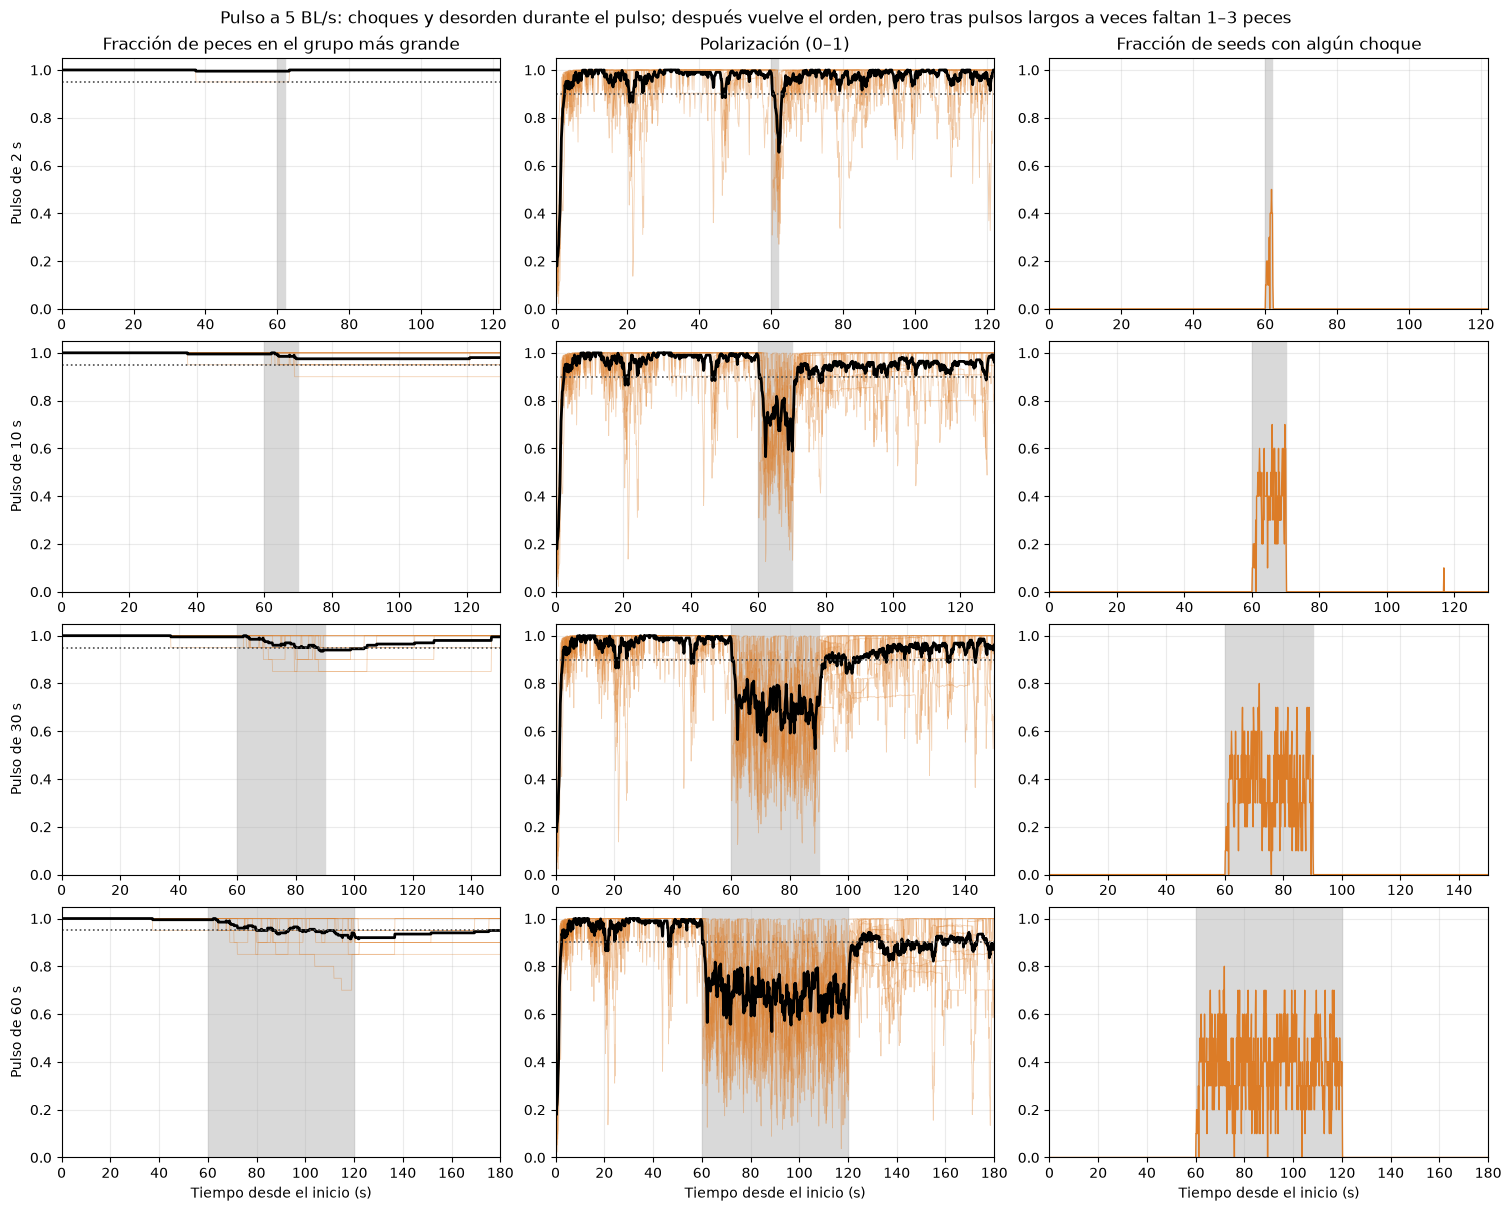

In [19]:
plot_pulse_figure(all_timeseries, 5.0, PUCKETT_COLOR, "Pulso a 5 BL/s: choques y desorden durante el pulso; después vuelve el orden, pero tras pulsos largos a veces faltan 1–3 peces", "pulse_5.png")

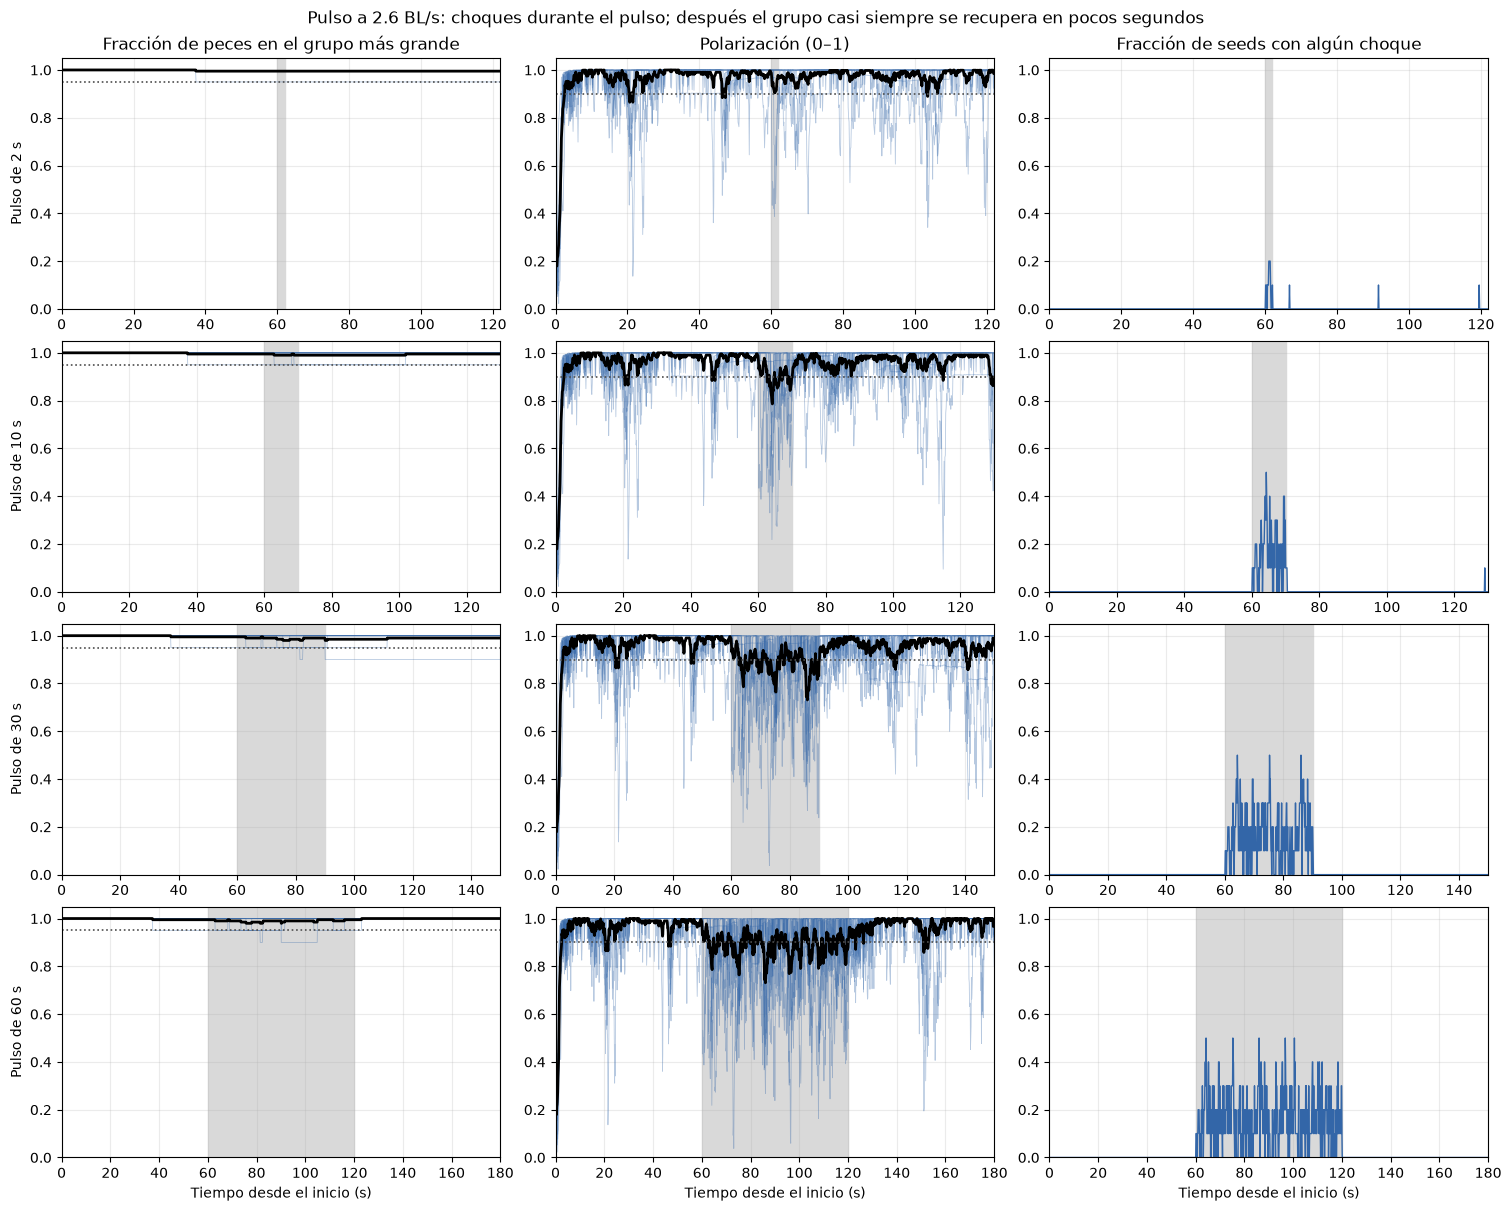

In [20]:
plot_pulse_figure(all_timeseries, 2.6, A0_COLOR, "Pulso a 2.6 BL/s: choques durante el pulso; después el grupo casi siempre se recupera en pocos segundos", "pulse_2_6.png")

### Figura 2 — Tiempo de recuperación de cada corrida

Cada punto es una corrida. Líneas a 10 s y 60 s. Las corridas que no se recuperaron se dibujan arriba, con otro símbolo.

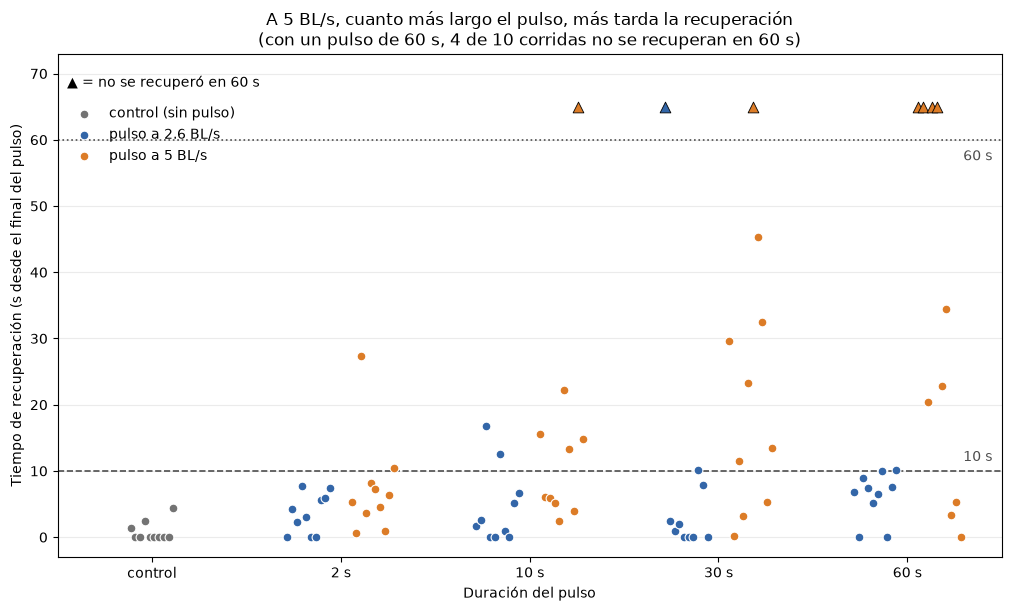

In [21]:
NEVER_HEIGHT = 65    # where the runs that never recovered are drawn


def recovery_points(runs, center):
    """x positions (slightly spread so the dots do not hide each other) and recovery times."""
    recovered_x = []
    recovered_y = []
    never_x = []
    for index in range(len(runs)):
        x = center + (index - 4.5) * 0.025
        value = runs["recovery_time_s"].iloc[index]
        if np.isnan(value):
            never_x.append(x)
        else:
            recovered_x.append(x)
            recovered_y.append(value)
    return recovered_x, recovered_y, never_x


ALL_DURATIONS = [CONTROL_SECONDS] + PULSE_DURATIONS    # one place on the x axis for each

fig, axis = plt.subplots(figsize=(10, 6), constrained_layout=True)
groups = [(CONTROL_SPEED, [CONTROL_SECONDS], "0.45", 0.0, "control (sin pulso)"),
          (2.6, PULSE_DURATIONS, A0_COLOR, -0.17, "pulso a 2.6 BL/s"),
          (5.0, PULSE_DURATIONS, PUCKETT_COLOR, 0.17, "pulso a 5 BL/s")]
never_drawn = False
for pulse_speed, durations, color, offset, label in groups:
    for pulse_seconds in durations:
        runs = all_summaries[(all_summaries["pulse_speed"] == pulse_speed)
                             & (all_summaries["pulse_seconds"] == pulse_seconds)]
        center = ALL_DURATIONS.index(pulse_seconds) + offset
        recovered_x, recovered_y, never_x = recovery_points(runs, center)
        axis.scatter(recovered_x, recovered_y, color=color, s=40, edgecolor="white", linewidth=0.8,
                     label=label, zorder=3)
        label = None    # only one legend entry per group
        if len(never_x) > 0:
            axis.scatter(never_x, [NEVER_HEIGHT] * len(never_x), color=color, marker="^", s=60,
                         edgecolor="black", linewidth=0.6, zorder=3)
            never_drawn = True

axis.axhline(10, color="0.3", linestyle="--", linewidth=1.2)
axis.axhline(60, color="0.3", linestyle=":", linewidth=1.2)
axis.text(4.45, 11, "10 s", ha="right", va="bottom", color="0.3")
axis.text(4.45, 58.5, "60 s", ha="right", va="top", color="0.3")
if never_drawn:
    axis.text(-0.45, NEVER_HEIGHT + 2.5, "▲ = no se recuperó en 60 s", ha="left", va="bottom")
axis.set_xticks(range(5))
axis.set_xticklabels(["control", "2 s", "10 s", "30 s", "60 s"])
axis.set_xlim(-0.5, 4.5)
axis.set_ylim(-3, NEVER_HEIGHT + 8)
axis.set_xlabel("Duración del pulso")
axis.set_ylabel("Tiempo de recuperación (s desde el final del pulso)")
axis.grid(alpha=0.25, axis="y")
axis.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92))
axis.set_title("A 5 BL/s, cuanto más largo el pulso, más tarda la recuperación\n(con un pulso de 60 s, 4 de 10 corridas no se recuperan en 60 s)")
fig.savefig(FIGURE_FOLDER / "pulse_recovery.png", dpi=150)
plt.show()

## Parte B — Memoria con la velocidad (subir y bajar)

Como el experimento de memoria del estudio 1, pero cambiando la velocidad en vez de r_o. En **una sola simulación larga**: 60 s de calentamiento a 0.2 BL/s; después la velocidad sube por 0.2, 0.5, 1, 1.6, 2, 2.6, 3.5 y 5 BL/s y vuelve a bajar por los mismos valores. Con cada valor nadamos 30 s (240 decisiones) y medimos el último tercio (80 decisiones).

In [22]:
RAMP_SPEEDS = [0.2, 0.5, 1.0, 1.6, 2.0, 2.6, 3.5, 5.0]
RAMP_WARM_UP_SPEED = 0.2
SECONDS_PER_SPEED = 30


def measure_speed_value(model, speed, n_decisions):
    """Swim n_decisions decisions at `speed` and summarise the last third."""
    set_speed(model, speed)
    moments = []
    for decision in range(1, n_decisions + 1):
        model.step()
        if decision > n_decisions - n_decisions // 3:
            moments.append(measure_moment(model))
    return {
        "polarization": average(moments, "polarization"),
        "largest_fraction": average(moments, "largest_fraction"),
        "collision_fraction": fraction_of_moments(moments, has_collision),
        "min_pair_distance": smallest(moments, "closest_pair"),
    }


def run_ramp(settings, seed):
    """One long run: warm-up at 0.2 BL/s, then the speed goes up and back down."""
    dt = settings["dt"]
    model = build_model(settings, seed)

    # Warm-up: 60 s at 0.2 BL/s, not measured.
    set_speed(model, RAMP_WARM_UP_SPEED)
    for _ in range(seconds_to_decisions(WARM_UP_SECONDS, dt)):
        model.step()

    going_up = RAMP_SPEEDS
    going_down = list(reversed(RAMP_SPEEDS))
    rows = []
    for direction, speeds in [("subiendo", going_up), ("bajando", going_down)]:
        for speed in speeds:
            row = {"seed": seed, "direction": direction, "speed": speed}
            row.update(measure_speed_value(model, speed, seconds_to_decisions(SECONDS_PER_SPEED, dt)))
            rows.append(row)
    return rows

Corremos las 10 seeds (o cargamos el archivo si ya existe).

In [23]:
ramp_path = DATA_FOLDER / "ramp.csv"
if ramp_path.exists() and not study_tools.RERUN:
    print("Loaded saved results from", ramp_path.name)
else:
    ramp_rows = []
    start_time = time.perf_counter()
    for seed in SEEDS:
        ramp_rows.extend(run_ramp(PULSE_SETTINGS, seed))
        print(f"seed {seed} done ({(time.perf_counter() - start_time) / 60:.1f} min so far)", flush=True)
    pd.DataFrame(ramp_rows).to_csv(ramp_path, index=False)
ramp = load_results(ramp_path)

RAMP_COLUMNS = ["polarization", "largest_fraction", "collision_fraction", "min_pair_distance"]
ramp_summary = ramp.groupby(["direction", "speed"], sort=False)[RAMP_COLUMNS].agg(["mean", "sem"])
ramp_summary

Loaded saved results from ramp.csv


polarization            largest_fraction        collision_fraction        min_pair_distance       
                        mean        sem             mean    sem               mean    sem              mean    sem
direction speed                                                                                                   
subiendo  0.2          0.990  5.978e-03            1.000  0.000              0.000  0.000             0.492  0.004
          0.5          0.989  8.568e-03            1.000  0.000              0.000  0.000             0.467  0.014
          1.0          0.986  5.484e-03            1.000  0.000              0.000  0.000             0.396  0.030
          1.6          0.964  7.551e-03            0.995  0.005              0.016  0.007             0.256  0.028
          2.0          0.921  1.191e-02            0.990  0.007              0.076  0.012             0.112  0.018
          2.6          0.887  1.777e-02            0.983  0.009              0.165  0.029             0.053  0.007
          3.5          0.824  1.209e-02            0.986  0.007              0.274  0.020             0.048  0.005
          5.0          0.694  2.174e-02            0.960  0.014              0.375  0.034             0.034  0.005
bajando   5.0          0.689  2.610e-02            0.961  0.019              0.410  0.023             0.032  0.004
          3.5          0.756  2.528e-02            0.951  0.025              0.312  0.041             0.048  0.007
          2.6          0.884  1.264e-02            0.977  0.011              0.144  0.015             0.058  0.008
          2.0          0.946  7.163e-03            0.997  0.003              0.051  0.010             0.159  0.025
          1.6          0.945  1.101e-02            1.000  0.000              0.033  0.010             0.203  0.019
          1.0          0.973  7.875e-03            1.000  0.000              0.000  0.000             0.357  0.022
          0.5          0.999  6.111e-04            1.000  0.000              0.000  0.000             0.508  0.006
          0.2          0.999  5.720e-04            1.000  0.000              0.000  0.000             0.511  0.004

Subiendo y bajando, lado a lado (medias de las 10 seeds).

In [24]:
ramp_means = ramp.groupby(["direction", "speed"], sort=False)[RAMP_COLUMNS].mean()
side_by_side = pd.DataFrame(index=RAMP_SPEEDS)
side_by_side.index.name = "speed (BL/s)"
for column in ["polarization", "largest_fraction", "collision_fraction"]:
    side_by_side[column + " subiendo"] = ramp_means.loc["subiendo", column].reindex(RAMP_SPEEDS).values
    side_by_side[column + " bajando"] = ramp_means.loc["bajando", column].reindex(RAMP_SPEEDS).values
side_by_side

,polarization subiendo,polarization bajando,largest_fraction subiendo,largest_fraction bajando,collision_fraction subiendo,collision_fraction bajando
speed (BL/s),,,,,,
0.2,0.990,0.999,1.000,1.000,0.000,0.000
0.5,0.989,0.999,1.000,1.000,0.000,0.000
1.0,0.986,0.973,1.000,1.000,0.000,0.000
1.6,0.964,0.945,0.995,1.000,0.016,0.033
2.0,0.921,0.946,0.990,0.997,0.076,0.051
2.6,0.887,0.884,0.983,0.977,0.165,0.144
3.5,0.824,0.756,0.986,0.951,0.274,0.312
5.0,0.694,0.689,0.960,0.961,0.375,0.410


### Figura 3 — ¿Se acuerda el grupo de haber ido rápido?

Línea llena: subiendo la velocidad. Línea punteada: bajando. Media ± error estándar de 10 seeds. La línea vertical punteada marca 1.6 BL/s (largo de paso 0.2 BL, el límite del estudio 3).

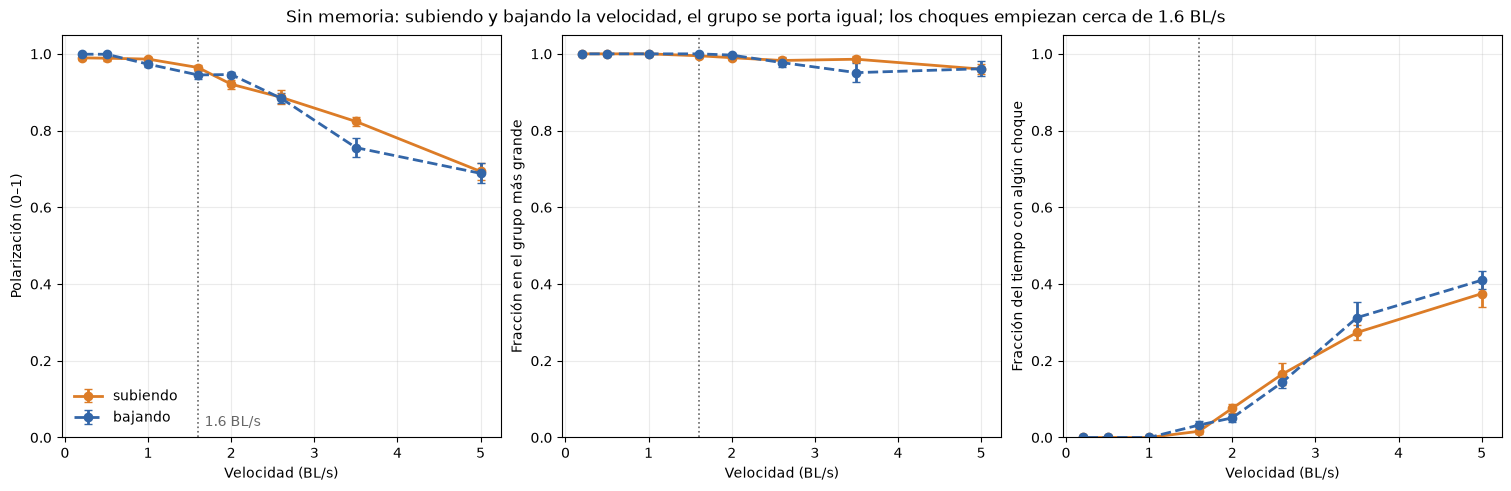

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
panels = [("polarization", "Polarización (0–1)"),
          ("largest_fraction", "Fracción en el grupo más grande"),
          ("collision_fraction", "Fracción del tiempo con algún choque")]
for axis, (column, axis_label) in zip(axes, panels):
    for direction, line_style, color in [("subiendo", "-", PUCKETT_COLOR), ("bajando", "--", A0_COLOR)]:
        rows = ramp_summary.loc[direction]
        axis.errorbar(rows.index, rows[(column, "mean")], yerr=rows[(column, "sem")],
                      color=color, linestyle=line_style, marker="o", markersize=6, linewidth=2,
                      capsize=3, label=direction)
    axis.axvline(1.6, color="0.4", linestyle=":", linewidth=1.2)
    axis.set_xlabel("Velocidad (BL/s)")
    axis.set_ylabel(axis_label)
    axis.set_ylim(0, 1.05)
    axis.grid(alpha=0.25)
axes[0].legend(frameon=False, loc="lower left")
axes[0].text(1.68, 0.03, "1.6 BL/s", color="0.4")
fig.suptitle("Sin memoria: subiendo y bajando la velocidad, el grupo se porta igual; los choques empiezan cerca de 1.6 BL/s")
fig.savefig(FIGURE_FOLDER / "ramp_memory.png", dpi=150)
plt.show()

## Qué vimos

- **Decisión según la regla del README: A tiene un problema real.** Con 5 BL/s durante 60 s, 4 de 10 seeds no se recuperan en 60 s (la regla permite como máximo 1).
- **El daño es pasajero, pero a veces lento.** En las corridas que fallan, el grupo no está roto: quedan 1 a 3 peces sueltos. En la prueba extra de 300 s, las 7 corridas que habían fallado se recuperan (entre 70 y 167 s después del pulso).
- **Durante el pulso el daño es grande:** a 5 BL/s hay algún choque en el 25–38 % de las decisiones y la polarización baja a unos 0.7.
- **A 2.6 BL/s casi no hay problema:** de 8 a 10 de las 10 seeds se recuperan en 10 s, y solo una corrida no se recupera en 60 s.
- **Sin memoria (parte B):** al bajar la velocidad, el grupo vuelve a ser como al subir. Los choques empiezan cerca de 1.6 BL/s, como en el estudio 3.
- **Ojo con el criterio:** incluso sin pulso, la polarización baja un momento cuando el grupo rebota en una pared. Por eso tiempos de recuperación de menos de unos 5 s son ruido.